# Phase 3 Technical Appendix - KIC-BSCCSAI-251P-050
**Paper under review:** Rizk-Allah et al. (2024), *Explainable AI and optimized solar power generation
forecasting model based on environmental conditions*



In [ ]:
import os, sys, time, json, warnings
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import sklearn
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import ParameterGrid
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
DATA_DIR = next(d for d in [HERE, os.path.dirname(HERE), os.getcwd()]
                if os.path.exists(os.path.join(d, "Plant_1_Generation_Data.csv")))
OUT_DIR = os.path.join(HERE, "outputs"); os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
pd.set_option("display.width", 170, "display.max_columns", 40)
WEATHER = ["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]
RES = {}                                  # every number used in the report ends up here
T0 = time.time()
def log(*a): print(f"[{time.time()-T0:6.0f}s]", *a, flush=True)
def save(df, name): df.to_csv(os.path.join(OUT_DIR, name)); return df
log("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__)

[     0s] pandas 3.0.6 | numpy 2.4.6 | sklearn 1.9.1 | torch 2.14.1+cpu


## 0. Data loading and audit (same corrected merge as Phase 2)

In [ ]:
FMT = {1: "%d-%m-%Y %H:%M", 2: "%Y-%m-%d %H:%M:%S"}      # generation-file date formats

def load_raw(plant):
    g = pd.read_csv(os.path.join(DATA_DIR, f"Plant_{plant}_Generation_Data.csv"))
    w = pd.read_csv(os.path.join(DATA_DIR, f"Plant_{plant}_Weather_Sensor_Data.csv"))
    return g, w

def correct_merge(plant):
    # Explicit date format per file; join on plant + timestamp (the weather file has ONE sensor key).
    g, w = load_raw(plant)
    g["DATE_TIME"] = pd.to_datetime(g["DATE_TIME"], format=FMT[plant])
    w["DATE_TIME"] = pd.to_datetime(w["DATE_TIME"], format="%Y-%m-%d %H:%M:%S")
    m = g.merge(w.drop(columns="SOURCE_KEY"), on=["DATE_TIME", "PLANT_ID"], how="inner")
    return m.sort_values(["DATE_TIME", "SOURCE_KEY"]).reset_index(drop=True), w

def paper_merge_plant1():
    # Re-creates the paper's 45,680-row table: generation dates read MONTH-first (the error found in Phase 1).
    g, w = load_raw(1)
    g["DATE_TIME"] = pd.to_datetime(g["DATE_TIME"], format="mixed", dayfirst=False)
    w["DATE_TIME"] = pd.to_datetime(w["DATE_TIME"])
    m = g.merge(w.drop(columns="SOURCE_KEY"), on=["DATE_TIME", "PLANT_ID"])
    return m.sort_values(["DATE_TIME", "SOURCE_KEY"]).reset_index(drop=True)

paper_df = paper_merge_plant1()
p1, w1 = correct_merge(1)
assert len(paper_df) == 45680 and paper_df.DATE_TIME.dt.date.nunique() == 23
assert len(p1) == 68774 and p1.DATE_TIME.dt.date.nunique() == 34
assert abs(paper_df.DC_POWER.mean() - 3197.18) < 0.05
log("OK - Phase 1/2 facts reproduced: paper table 45,680 rows / 23 days / mean DC 3,197.18; correct merge 68,774 rows / 34 days")

[     1s] OK - Phase 1/2 facts reproduced: paper table 45,680 rows / 23 days / mean DC 3,197.18; correct merge 68,774 rows / 34 days


## 1. Evaluation helpers, models, and an LSTM *proxy*
The paper reports a single-step LSTM (no window length given): 24 units after EO tuning, Adam, 45 epochs,
batch size 10 (Phase 1, Section 4.3). `LSTMProxy` mirrors that with `seq_len = 1`; with `seq_len > 1` it
becomes a genuine sequence model, which the paper never uses.

In [ ]:
def metrics(y, p, day=None):
    out = {"RMSE": mean_squared_error(y, p) ** .5, "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}
    if day is not None and day.sum() > 1:
        out.update({"RMSE_day": mean_squared_error(y[day], p[day]) ** .5,
                    "MAE_day": mean_absolute_error(y[day], p[day]), "R2_day": r2_score(y[day], p[day])})
    return out

def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def chrono_split(index, n_train=24, n_val=5):
    # Whole days in time order: first 24 -> train, next 5 -> validation, remaining 5 -> test.
    d = pd.DatetimeIndex(index).normalize()
    days = np.array(sorted(d.unique()))
    tr, va, te = days[:n_train], days[n_train:n_train + n_val], days[n_train + n_val:]
    return np.asarray(d.isin(tr)), np.asarray(d.isin(va)), np.asarray(d.isin(te)), (tr, va, te)

class _Net(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.lstm = nn.LSTM(d, hidden, batch_first=True); self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.fc(o[:, -1, :]).squeeze(-1)

class LSTMProxy:
    """LSTM regressor: scaler fitted on training data only, target standardised on training data only."""
    def __init__(self, hidden=24, epochs=45, batch=10, lr=0.01, seed=SEED, seq_len=1):
        self.hidden, self.epochs, self.batch, self.lr, self.seed, self.seq_len = hidden, epochs, batch, lr, seed, seq_len
    def _prep(self, X):
        X = np.asarray(X, dtype=np.float64); n = len(X)
        Z = self.sx.transform(X.reshape(n * self.seq_len, -1))
        return torch.tensor(Z.reshape(n, self.seq_len, -1), dtype=torch.float32)
    def fit(self, X, y):
        torch.manual_seed(self.seed)
        X = np.asarray(X, dtype=np.float64); y = np.asarray(y, dtype=np.float64); n = len(X)
        self.sx = StandardScaler().fit(X.reshape(n * self.seq_len, -1))
        self.my, self.sy = y.mean(), y.std() + 1e-9
        Xt = self._prep(X); yt = torch.tensor((y - self.my) / self.sy, dtype=torch.float32)
        self.net = _Net(Xt.shape[2], self.hidden); opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        g = torch.Generator().manual_seed(self.seed); loss_fn = nn.MSELoss()
        self.net.train()
        for _ in range(self.epochs):
            perm = torch.randperm(n, generator=g)
            for i in range(0, n, self.batch):
                b = perm[i:i + self.batch]
                opt.zero_grad(); loss_fn(self.net(Xt[b]), yt[b]).backward(); opt.step()
        return self
    def predict(self, X):
        self.net.eval()
        with torch.no_grad(): return self.net(self._prep(X)).numpy().astype(np.float64) * self.sy + self.my
    def n_params(self): return sum(p.numel() for p in self.net.parameters())

def make(name, bp=None, seed=SEED):
    bp = bp or {}
    if name == "Ridge":         return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))
    if name == "Random forest": return RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=seed, **bp)
    if name == "HistGB":        return HistGradientBoostingRegressor(random_state=seed, **bp)
    if name == "MLP":           return make_pipeline(StandardScaler(), MLPRegressor(early_stopping=True, max_iter=400, random_state=seed, **bp))
    if name == "LSTM proxy":    return LSTMProxy(seed=seed, **bp)
    if name == "LSTM (window 8)": return LSTMProxy(seed=seed, seq_len=8, **bp)
    raise KeyError(name)

GRIDS = {   # identical grids to Phase 2 (small by design); LSTM grid = learning rate only (paper used 0.1, unsearched)
    "Random forest": {"min_samples_leaf": [5, 20, 50], "max_features": [1.0, 0.67]},
    "HistGB": {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [8, 16, 31], "l2_regularization": [0, 1.0]},
    "MLP": {"hidden_layer_sizes": [(16,), (32, 16), (64, 32)], "alpha": [1e-4, 1e-2]},
    "LSTM proxy": {"lr": [0.1, 0.01, 0.001]},
    "LSTM (window 8)": {"lr": [0.01, 0.001]},
}

def tune(name, Xtr, ytr, Xva, yva, seed=SEED):
    """Hyper-parameters chosen on the VALIDATION days only (the paper selected on training MSE)."""
    grid = GRIDS.get(name)
    if not grid: return {}, None
    rows = []
    for params in ParameterGrid(grid):
        m = make(name, params, seed).fit(Xtr, ytr)
        rows.append({**params, "val_RMSE": rmse(yva, m.predict(Xva))})
    t = pd.DataFrame(rows).sort_values("val_RMSE")
    best = {k: t.iloc[0][k] for k in grid}
    for k in best:                                  # restore python types (tuples/ints) from the DataFrame
        if isinstance(grid[k][0], tuple): best[k] = next(v for v in grid[k] if str(v) == str(best[k]))
        elif isinstance(grid[k][0], int) and not isinstance(grid[k][0], bool): best[k] = int(best[k])
        elif isinstance(grid[k][0], float) or isinstance(grid[k][0], int): best[k] = float(best[k])
    return best, t

### 1a. Does an LSTM proxy beat simple models on the paper's own table?
Paper's 45,680-row table, `DC_POWER/1000`, three weather inputs, random 80/20 split (repeated over 3 seeds: 0, 1, 2, extending Experiment A's protocol).
Batch size 64 is used here (instead of 10) purely to keep runtime reasonable on 36,544 rows; learning rate
0.1 is the paper's setting, 0.01 is a conventional alternative.

In [ ]:
Xp = paper_df[WEATHER].values; yp = paper_df["DC_POWER"].values / 1000
dayp = paper_df["IRRADIATION"].values > 0
ts = paper_df["DATE_TIME"].values
floor_paper = rmse(yp, pd.Series(yp).groupby(ts).transform("mean").values)
RES["floor_paper_rmse"] = floor_paper
rows = []
for s in [0, 1, 2]:
    idx = np.random.RandomState(s).permutation(len(yp)); cut = int(.8 * len(yp)); tr_, te_ = idx[:cut], idx[cut:]
    m = DecisionTreeRegressor(random_state=s).fit(Xp[tr_], yp[tr_])
    rows.append({"model": "Decision tree (untuned)", "seed": s, "lr": np.nan, **metrics(yp[te_], m.predict(Xp[te_]), dayp[te_])})
    for lr in [0.1, 0.01]:
        t = time.time(); m = LSTMProxy(lr=lr, batch=64, seed=s).fit(Xp[tr_], yp[tr_])
        rows.append({"model": f"LSTM proxy (24 units, lr={lr})", "seed": s, "lr": lr, **metrics(yp[te_], m.predict(Xp[te_]), dayp[te_])})
        log(f"paper-table LSTM proxy seed {s} lr {lr}: RMSE {rows[-1]['RMSE']:.3f} ({time.time()-t:.0f}s)")
E1 = pd.DataFrame(rows)
E1_tab = E1.groupby("model")[["RMSE", "MAE", "R2", "RMSE_day"]].agg(["mean", "std"]).round(3)
display = print; display(E1_tab); save(E1_tab, "e1_lstm_proxy_on_paper_table.csv")
RES["paper_table"] = {k: {"RMSE": float(E1[E1.model == k].RMSE.mean()), "RMSE_sd": float(E1[E1.model == k].RMSE.std()),
                          "MAE": float(E1[E1.model == k].MAE.mean()), "R2": float(E1[E1.model == k].R2.mean()),
                          "RMSE_day": float(E1[E1.model == k].RMSE_day.mean())} for k in E1.model.unique()}

[    55s] paper-table LSTM proxy seed 0 lr 0.1: RMSE 0.560 (55s)
[    99s] paper-table LSTM proxy seed 0 lr 0.01: RMSE 0.547 (44s)
[   143s] paper-table LSTM proxy seed 1 lr 0.1: RMSE 0.567 (44s)
[   190s] paper-table LSTM proxy seed 1 lr 0.01: RMSE 0.508 (46s)
[   240s] paper-table LSTM proxy seed 2 lr 0.1: RMSE 0.553 (50s)
[   335s] paper-table LSTM proxy seed 2 lr 0.01: RMSE 0.528 (95s)
                                 RMSE           MAE            R2        RMSE_day       
                                 mean    std   mean    std   mean    std     mean    std
model                                                                                   
Decision tree (untuned)         0.471  0.023  0.173  0.003  0.987  0.001    0.626  0.032
LSTM proxy (24 units, lr=0.01)  0.528  0.019  0.234  0.006  0.983  0.001    0.701  0.028
LSTM proxy (24 units, lr=0.1)   0.560  0.007  0.311  0.021  0.981  0.000    0.735  0.010


## 2. Plant-level frame and feature builders (as Phase 2, plus lag features)
One target per input: mean DC power of the reporting inverters per 15-minute slot (`/1000`).
Every feature uses only information available at time *t*.

In [ ]:
def plant_frame(merged, weather_df):
    pw = merged.groupby("DATE_TIME")["DC_POWER"].mean() / 1000
    grid = pd.date_range(merged.DATE_TIME.min().normalize(), merged.DATE_TIME.max().normalize() + pd.Timedelta("23h45min"), freq="15min")
    df = pd.DataFrame(index=grid); df["power"] = pw
    df = df.join(weather_df.set_index("DATE_TIME")[WEATHER])
    return df

PF = plant_frame(p1, w1)
log(f"plant frame: {len(PF)} slots | with power {PF.power.notna().sum()} | with weather {PF.IRRADIATION.notna().sum()}")

BASE6 = WEATHER + ["tod_sin", "tod_cos", "irr_lag1"]                        # Phase 2 nowcast inputs
BASE = BASE6 + ["power_t"]                                                  # Phase 2 forecast inputs
ENRICH = BASE + ["power_lag1", "power_lag2", "power_lag3", "irr_lag2", "irr_lag3", "mod_lag1", "irr_roll4", "power_roll4"]
SEQ_COLS = ["IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "power", "tod_sin", "tod_cos"]
W = 8
SEQ = [f"{c}_L{k}" for k in range(W - 1, -1, -1) for c in SEQ_COLS]        # oldest -> newest, lag-major

def build(df, h, union=False):
    """Supervised frame for horizon h (steps of 15 min). union=True keeps only rows valid for EVERY feature set."""
    f = df.copy()
    mins = f.index.hour * 60 + f.index.minute
    f["tod_sin"] = np.sin(2 * np.pi * mins / 1440); f["tod_cos"] = np.cos(2 * np.pi * mins / 1440)
    f["irr_lag1"] = f.IRRADIATION.shift(1); f["power_t"] = f.power
    f["target"] = f.power.shift(-h); f["irr_target"] = f.IRRADIATION.shift(-h)
    if union:
        for k in (1, 2, 3): f[f"power_lag{k}"] = f.power.shift(k)
        f["irr_lag2"] = f.IRRADIATION.shift(2); f["irr_lag3"] = f.IRRADIATION.shift(3); f["mod_lag1"] = f.MODULE_TEMPERATURE.shift(1)
        f["irr_roll4"] = f.IRRADIATION.rolling(4).mean(); f["power_roll4"] = f.power.rolling(4).mean()
        for k in range(W):
            for c in SEQ_COLS: f[f"{c}_L{k}"] = f[c].shift(k)
        need = list(dict.fromkeys(ENRICH + SEQ + ["target", "irr_target"]))
    else:
        need = BASE6 + (["power_t"] if h > 0 else []) + ["target", "irr_target"]
    n0 = len(f); f = f.dropna(subset=need)
    return f, n0 - len(f)

class Climatology:
    def fit(self, slot, y): self.m = pd.Series(y).groupby(slot).mean(); return self
    def predict(self, slot): return pd.Series(slot).map(self.m).fillna(0).values

def target_slot(f, h):
    t = f.index + h * pd.Timedelta("15min"); return (t.hour * 60 + t.minute).values

[   335s] plant frame: 3264 slots | with power 3157 | with weather 3182


## 3. Nowcast (h = 0) with tuned models incl. the LSTM proxy - the paper's task on the corrected protocol

In [ ]:
f0, drop0 = build(PF, 0)
tr0, va0, te0, (dtr, dva, dte) = chrono_split(f0.index)
X0, y0 = f0[BASE6].values, f0.target.values; day0 = f0.irr_target.values > 0
log(f"nowcast rows {len(f0)} (dropped {drop0}) | train {tr0.sum()} val {va0.sum()} test {te0.sum()} | "
    f"test days {pd.Timestamp(dte[0]).date()}..{pd.Timestamp(dte[-1]).date()}")
RES["split"] = {"train_days": len(dtr), "val_days": len(dva), "test_days": len(dte), "n_rows": int(len(f0)),
                "test_first": str(pd.Timestamp(dte[0]).date()), "test_last": str(pd.Timestamp(dte[-1]).date())}
NOW_MODELS = ["Ridge", "Random forest", "HistGB", "MLP", "LSTM proxy"]
BP0, nowcast_rows, tune_tabs = {}, [], {}
clim0 = Climatology().fit(target_slot(f0, 0)[tr0 | va0], y0[tr0 | va0])
nowcast_rows.append({"model": "Climatology", "seeds": 1, **metrics(y0[te0], clim0.predict(target_slot(f0, 0)[te0]), day0[te0]), "RMSE_day_sd": 0.0})
SEEDS = [0, 1, 2]
for name in NOW_MODELS:
    bp, tt = tune(name, X0[tr0], y0[tr0], X0[va0], y0[va0]); BP0[name] = bp; tune_tabs[name] = tt
    stoch = name in ("MLP", "LSTM proxy")
    rs = []
    for s in (SEEDS if stoch else [SEED]):
        m = make(name, bp, s).fit(X0[tr0 | va0], y0[tr0 | va0]); rs.append(metrics(y0[te0], m.predict(X0[te0]), day0[te0]))
    r = pd.DataFrame(rs).mean().to_dict(); r["RMSE_day_sd"] = pd.DataFrame(rs).RMSE_day.std() if stoch else 0.0
    nowcast_rows.append({"model": name, "seeds": len(rs), **r}); log("nowcast", name, bp, f"RMSE_day {r['RMSE_day']:.3f}")
NOW = pd.DataFrame(nowcast_rows).set_index("model").round(4); print(NOW); save(NOW, "e2_nowcast_tuned.csv")
RES["nowcast"] = {k: {"RMSE": float(v.RMSE), "RMSE_day": float(v.RMSE_day), "MAE": float(v.MAE), "R2": float(v.R2),
                      "RMSE_day_sd": float(v.RMSE_day_sd)} for k, v in NOW.iterrows()}
RES["nowcast_best_params"] = {k: {a: (list(b) if isinstance(b, tuple) else b) for a, b in v.items()} for k, v in BP0.items()}
RES["nowcast_lstm_lr_table"] = tune_tabs["LSTM proxy"].round(4).to_dict("records")

[   335s] nowcast rows 3148 (dropped 116) | train 2190 val 480 test 478 | test days 2020-06-13..2020-06-17
[   335s] nowcast Ridge {} RMSE_day 0.396
[   337s] nowcast Random forest {'min_samples_leaf': 5, 'max_features': 1.0} RMSE_day 0.311
[   339s] nowcast HistGB {'learning_rate': 0.1, 'max_leaf_nodes': 8, 'l2_regularization': 0} RMSE_day 0.309
[   343s] nowcast MLP {'hidden_layer_sizes': (64, 32), 'alpha': 0.01} RMSE_day 0.360
[   445s] nowcast LSTM proxy {'lr': 0.001} RMSE_day 0.282
               seeds    RMSE     MAE      R2  RMSE_day  MAE_day  R2_day  RMSE_day_sd
model                                                                               
Climatology        1  1.3690  0.7053  0.8714    1.8456   1.2819  0.7508       0.0000
Ridge              1  0.3004  0.1944  0.9938    0.3961   0.2860  0.9885       0.0000
Random forest      1  0.2305  0.1075  0.9964    0.3107   0.1954  0.9929       0.0000
HistGB             1  0.2296  0.1144  0.9964    0.3095   0.2047  0.9930       0.000

## 4. Proposed alternatives (forecast task, h = 1 and h = 4)
**Alternative A** - gradient boosting / ridge with lagged power and weather features (not used by the authors).
**Alternative B** - *probabilistic* forecasting: quantile gradient boosting with conformal calibration (CQR),
which quantifies residual forecast uncertainty around the plant-mean generation target.
All models are scored on the same rows (those with 2 h of complete history), daytime RMSE, skill vs persistence.

In [ ]:
def day_bootstrap(days, dm, fn, n=2000, seed=SEED):
    """Resample whole test days with replacement; fn(selected_row_indices) -> dict of statistics."""
    ud = np.unique(days); rng = np.random.RandomState(seed); out = []
    for _ in range(n):
        pick = rng.choice(ud, len(ud))
        sel = np.concatenate([np.where((days == d) & dm)[0] for d in pick]); out.append(fn(sel))
    return pd.DataFrame(out)

FC = {}
for h in (1, 4):
    f, dropped = build(PF, h, union=True)
    tr, va, te, _ = chrono_split(f.index)
    y = f.target.values; day = f.irr_target.values > 0; dm_te = day[te]
    sets = {"Phase-2 features": BASE, "Enriched lags": ENRICH, "Window 8": SEQ}
    preds, stats, bps = {}, {}, {}
    preds["Persistence"] = f.power_t.values[te]
    slot = target_slot(f, h); preds["Climatology"] = Climatology().fit(slot[tr | va], y[tr | va]).predict(slot[te])
    for nm, cols, mod in [("Ridge", BASE, "Ridge"), ("Ridge + lags", ENRICH, "Ridge"),
                          ("Random forest", BASE, "Random forest"), ("Random forest + lags", ENRICH, "Random forest"),
                          ("HistGB", BASE, "HistGB"), ("HistGB + lags (Alt. A)", ENRICH, "HistGB"),
                          ("LSTM proxy (window 1)", BASE, "LSTM proxy"), ("LSTM (window 8)", SEQ, "LSTM (window 8)")]:
        X = f[cols].values
        bp, _ = tune(mod, X[tr], y[tr], X[va], y[va]); bps[nm] = bp
        stoch = mod.startswith("LSTM")
        ps = [make(mod, bp, s).fit(X[tr | va], y[tr | va]).predict(X[te]) for s in (SEEDS if stoch else [SEED])]
        preds[nm] = ps[0] if not stoch else np.mean(ps, axis=0)
        stats[nm] = {"rmse_seeds": [rmse(y[te][dm_te], p[dm_te]) for p in ps]}
        log(f"h={h} {nm}: day RMSE {np.mean(stats[nm]['rmse_seeds']):.3f}")
    yt = y[te]; ref = rmse(yt[dm_te], preds["Persistence"][dm_te])
    rows = []
    for nm, p in preds.items():
        r = np.mean(stats[nm]["rmse_seeds"]) if nm in stats else rmse(yt[dm_te], p[dm_te])
        rows.append({"model": nm, "RMSE_day": r, "RMSE_day_sd": (np.std(stats[nm]["rmse_seeds"], ddof=1) if nm in stats and len(stats[nm]["rmse_seeds"]) > 1 else 0.0),
                     "MAE_day": mean_absolute_error(yt[dm_te], p[dm_te]), "R2_day": r2_score(yt[dm_te], p[dm_te]), "skill_vs_persistence": 1 - r / ref})
    T = pd.DataFrame(rows).set_index("model").round(4); print(f"\n=== forecast h={h} ({15*h} min) | rows {len(f)} test rows {te.sum()} ===\n", T)
    save(T, f"e3_forecast_h{h}.csv")
    # paired day-block bootstrap: skill vs persistence and the gain of lags over the Phase-2 feature set
    days = f.index[te].normalize().values
    def stat(sel):
        e = lambda p: rmse(yt[sel], p[sel]); per = e(preds["Persistence"])
        return {"skill_base": 1 - e(preds["HistGB"]) / per, "skill_alt": 1 - e(preds["HistGB + lags (Alt. A)"]) / per,
                "skill_ridge_lags": 1 - e(preds["Ridge + lags"]) / per,
                "d_rmse": e(preds["HistGB + lags (Alt. A)"]) - e(preds["HistGB"]),
                "d_rmse_rf": e(preds["Random forest + lags"]) - e(preds["Random forest"])}
    B = day_bootstrap(days, dm_te, stat); ci = {k: [float(np.percentile(B[k], 2.5)), float(np.percentile(B[k], 97.5))] for k in B}
    FC[h] = dict(f=f, tr=tr, va=va, te=te, y=y, preds=preds, T=T, ci=ci, bps=bps, dm_te=dm_te, days=days)
    RES[f"forecast_h{h}"] = {"rows": int(len(f)), "test_rows": int(te.sum()), "table": T.reset_index().to_dict("records"), "ci": ci,
                             "best_params_histgb_lags": {a: float(b) for a, b in bps["HistGB + lags (Alt. A)"].items()}}
    print({k: np.round(v, 3).tolist() for k, v in ci.items()})

[   445s] h=1 Ridge: day RMSE 1.407
[   445s] h=1 Ridge + lags: day RMSE 1.380
[   450s] h=1 Random forest: day RMSE 1.341
[   457s] h=1 Random forest + lags: day RMSE 1.335
[   463s] h=1 HistGB: day RMSE 1.352
[   469s] h=1 HistGB + lags (Alt. A): day RMSE 1.322
[   589s] h=1 LSTM proxy (window 1): day RMSE 1.327
[   686s] h=1 LSTM (window 8): day RMSE 1.313

=== forecast h=1 (15 min) | rows 3069 test rows 469 ===
                         RMSE_day  RMSE_day_sd  MAE_day  R2_day  skill_vs_persistence
model                                                                               
Persistence               1.4744       0.0000   1.0373  0.8429                0.0000
Climatology               1.8729       0.0000   1.3033  0.7464               -0.2703
Ridge                     1.4072       0.0000   0.9908  0.8568                0.0455
Ridge + lags              1.3802       0.0000   0.9744  0.8623                0.0639
Random forest             1.3408       0.0000   0.9009  0.8700        

### 4b. Alternative B - conformalised quantile regression
Lower/upper 10 % / 90 % quantile boosters are trained on the 24 training days; the 5 validation days calibrate the
interval; the 5 test days are used once. Nominal coverage = 80 %. Compared with a split-conformal interval of
constant width around the point forecast.

In [ ]:
Q = {}
for h in (1, 4):
    d = FC[h]; f, tr, va, te, y = d["f"], d["tr"], d["va"], d["te"], d["y"]
    X = f[ENRICH].values; day = f.irr_target.values > 0; bp = d["bps"]["HistGB + lags (Alt. A)"]
    qlo = HistGradientBoostingRegressor(loss="quantile", quantile=0.1, random_state=SEED, **bp).fit(X[tr], y[tr])
    qhi = HistGradientBoostingRegressor(loss="quantile", quantile=0.9, random_state=SEED, **bp).fit(X[tr], y[tr])
    point = HistGradientBoostingRegressor(random_state=SEED, **bp).fit(X[tr], y[tr])
    vm, tm = va & day, te & day; alpha = 0.2
    lo_v, hi_v, lo_t, hi_t = qlo.predict(X[vm]), qhi.predict(X[vm]), qlo.predict(X[tm]), qhi.predict(X[tm])
    s = np.maximum(lo_v - y[vm], y[vm] - hi_v); k = int(np.ceil((len(s) + 1) * (1 - alpha))); qhat = np.sort(s)[min(k, len(s)) - 1]
    res_v = np.abs(y[vm] - point.predict(X[vm])); k2 = int(np.ceil((len(res_v) + 1) * (1 - alpha))); r_hat = np.sort(res_v)[min(k2, len(res_v)) - 1]
    pt = point.predict(X[tm]); yt = y[tm]
    ints = {"Raw quantile (untrained calibration)": (lo_t, hi_t), "CQR (calibrated on val days)": (lo_t - qhat, hi_t + qhat),
            "Split conformal (constant width)": (pt - r_hat, pt + r_hat)}
    days_t = f.index[tm].normalize().values; rows = []
    for nm, (lo, hi) in ints.items():
        cov = np.mean((yt >= lo) & (yt <= hi)); wid = np.mean(hi - lo)
        bs = day_bootstrap(days_t, np.ones(len(yt), bool), lambda sel, lo=lo, hi=hi: {"cov": np.mean((yt[sel] >= lo[sel]) & (yt[sel] <= hi[sel]))})
        rows.append({"interval": nm, "coverage": cov, "cov_lo95": np.percentile(bs["cov"], 2.5), "cov_hi95": np.percentile(bs["cov"], 97.5), "mean_width": wid})
    QT = pd.DataFrame(rows).set_index("interval").round(3); print(f"\n=== intervals h={h} (nominal 80 %, daytime test rows {tm.sum()}) ===\n", QT)
    save(QT, f"e4_intervals_h{h}.csv"); Q[h] = dict(ints=ints, tm=tm, pt=pt, f=f, QT=QT)
    RES[f"intervals_h{h}"] = QT.reset_index().to_dict("records")

=== intervals h=1 (nominal 80 %, daytime test rows 255) ===
                                       coverage  cov_lo95  cov_hi95  mean_width
interval                                                                      
Raw quantile (untrained calibration)     0.890     0.858     0.922       6.979
CQR (calibrated on val days)             0.773     0.730     0.823       6.739
Split conformal (constant width)         0.780     0.761     0.802       2.723

=== intervals h=4 (nominal 80 %, daytime test rows 254) ===
                                       coverage  cov_lo95  cov_hi95  mean_width
interval                                                                      
Raw quantile (untrained calibration)     0.917     0.853     0.963       7.464
CQR (calibrated on val days)             0.760     0.679     0.838       6.925
Split conformal (constant width)         0.740     0.707     0.777       3.779


### 4c. Computational cost (the paper's LSTM vs the proposed boosting model), same training rows

In [ ]:
d = FC[1]; Xc, yc, trc = d["f"][ENRICH].values, d["y"], d["tr"] | d["va"]
def timeit(fn, n=3):
    ts_ = []
    for _ in range(n): t = time.perf_counter(); fn(); ts_.append(time.perf_counter() - t)
    return float(np.median(ts_))
bp_h = d["bps"]["HistGB + lags (Alt. A)"]
t_hgb = timeit(lambda: make("HistGB", bp_h).fit(Xc[trc], yc[trc]))
Xb = d["f"][BASE].values
t_ridge = timeit(lambda: make("Ridge").fit(Xb[trc], yc[trc]))
lstm1 = make("LSTM proxy", {"lr": 0.01}); t_lstm = timeit(lambda: lstm1.fit(Xb[trc], yc[trc]), 2)
lstmw = make("LSTM (window 8)", {"lr": 0.01}); t_lstmw = timeit(lambda: lstmw.fit(d["f"][SEQ].values[trc], yc[trc]), 2)
COST = pd.DataFrame({"fit_seconds": [t_ridge, t_hgb, t_lstm, t_lstmw],
                     "parameters": [len(ENRICH) + 1, "~" + str(bp_h.get("max_leaf_nodes", 31)) + " leaves x 100 trees", lstm1.n_params(), lstmw.n_params()]},
                    index=["Ridge", "HistGB + lags", "LSTM proxy (24 units, window 1, 45 epochs, batch 10)", "LSTM (24 units, window 8)"]).round(3)
print(COST); save(COST, "e5_cost.csv")
RES["cost"] = {"ridge_s": t_ridge, "histgb_s": t_hgb, "lstm_s": t_lstm, "lstm_w8_s": t_lstmw,
               "lstm_params": int(lstm1.n_params()), "lstm_w8_params": int(lstmw.n_params()), "train_rows": int(trc.sum())}

                                                    fit_seconds             parameters
Ridge                                                     0.004                     16
HistGB + lags                                             0.098  ~8 leaves x 100 trees
LSTM proxy (24 units, window 1, 45 epochs, batc...       20.492                   3193
LSTM (24 units, window 8)                                20.190                   3097


## 5. Stress tests on the nowcast (h = 0, plant level, 6 weather/time inputs)


In [ ]:
STRESS = ["Ridge", "Random forest", "HistGB", "MLP", "LSTM proxy"]
trv = tr0 | va0; dm0 = day0[te0]; Xtv, ytv, Xte_, yte_ = X0[trv], y0[trv], X0[te0], y0[te0]
sd = Xtv.std(0)

def fit_all(Xa, ya, seeds):
    return {n: [make(n, BP0[n], s).fit(Xa, ya) for s in (seeds if n in ("MLP", "LSTM proxy") else [SEED])] for n in STRESS}
def eval_rm(models, Xe):
    return {n: float(np.mean([rmse(yte_[dm0], m.predict(Xe)[dm0]) for m in ms])) for n, ms in models.items()}

base_models = fit_all(Xtv, ytv, SEEDS)
S0 = eval_rm(base_models, Xte_); log("stress baseline", {k: round(v, 3) for k, v in S0.items()})

# (a) Gaussian noise on test weather inputs; 5 noise draws averaged
sigmas = [0, .05, .1, .2, .4]; rows = []
for sg in sigmas:
    acc = {n: [] for n in STRESS}
    for r in range(5):
        rng = np.random.RandomState(100 + r); Xn = Xte_.copy(); Xn[:, :3] += rng.normal(size=Xn[:, :3].shape) * sd[:3] * sg
        for n, v in eval_rm(base_models, Xn).items(): acc[n].append(v)
    rows.append({"sigma": sg, **{n: np.mean(v) for n, v in acc.items()}})
NOISE = pd.DataFrame(rows).set_index("sigma"); print(NOISE.round(3)); save(NOISE.round(4), "e6_noise.csv")
sens = {n: float(np.sum((NOISE[n].values[1:5] ** 2 - NOISE[n].values[0] ** 2) * np.array(sigmas[1:5]) ** 2) / np.sum(np.array(sigmas[1:5]) ** 4)) for n in STRESS}
# R^2 of the through-origin fit of RMSE^2 - RMSE_0^2 on sigma^2 (sigma <= 0.2)
def fit_r2(n):
    xx = np.array(sigmas[1:4]) ** 2; yy = NOISE[n].values[1:4] ** 2 - NOISE[n].values[0] ** 2; b = (xx @ yy) / (xx @ xx)
    return float(1 - ((yy - b * xx) ** 2).sum() / ((yy - yy.mean()) ** 2).sum())
RES["noise"] = {"table": NOISE.reset_index().round(4).to_dict("records"), "sensitivity": sens, "fit_r2_sigma_le_0.2": {n: fit_r2(n) for n in STRESS}}

# (b) irrelevant N(0,1) features appended to train and test; 3 repetitions x seeds averaged
ks = [0, 10, 50, 200]; rows = []
for k in ks:
    acc = {n: [] for n in STRESS}
    for r in range(3):
        R = np.random.RandomState(200 + r); Ztr, Zte = R.normal(size=(len(Xtv), k)), R.normal(size=(len(Xte_), k))
        mods = fit_all(np.hstack([Xtv, Ztr]), ytv, [r]) if k else base_models
        for n, v in eval_rm(mods, np.hstack([Xte_, Zte])).items(): acc[n].append(v)
        if not k: break
    rows.append({"extra_features": k, **{n: np.mean(v) for n, v in acc.items()}}); log("dims", k, {n: round(np.mean(v), 3) for n, v in acc.items()})
DIM = pd.DataFrame(rows).set_index("extra_features"); print(DIM.round(3)); save(DIM.round(4), "e7_dimensionality.csv")
RES["dimensionality"] = DIM.reset_index().round(4).to_dict("records")
RES["rows_per_feature_200"] = float(len(Xtv) / (Xtv.shape[1] + 200))

# (c) sensor outage: replace one weather channel in the TEST inputs by its training mean (imputation)
rows = []
for label, cols in [("none", []), ("irradiation lost (also lag1)", [2, 5]), ("module temp lost", [1]), ("ambient temp lost", [0])]:
    Xo = Xte_.copy()
    for c in cols: Xo[:, c] = Xtv[:, c].mean()
    rows.append({"scenario": label, **eval_rm(base_models, Xo)})
OUT = pd.DataFrame(rows).set_index("scenario"); print(OUT.round(3)); save(OUT.round(4), "e8_sensor_outage.csv")
RES["outage"] = OUT.reset_index().round(4).to_dict("records")
assert BASE6[2] == "IRRADIATION" and BASE6[5] == "irr_lag1"       # column indices used above: 2 and 5

# (d) data scarcity: train on the last n training days only (no validation days), fixed tuned hyper-parameters
days_tr = pd.DatetimeIndex(f0.index[tr0]).normalize(); ud = np.array(sorted(days_tr.unique())); rows = []
for n_days in [2, 4, 8, 16, 24]:
    keep = np.isin(days_tr, ud[-n_days:]); Xs_, ys_ = X0[tr0][keep], y0[tr0][keep]
    mods = fit_all(Xs_, ys_, SEEDS); rows.append({"train_days": n_days, "rows": int(keep.sum()), **eval_rm(mods, Xte_)}); log("scarcity", n_days)
SCAR = pd.DataFrame(rows).set_index("train_days"); print(SCAR.round(3)); save(SCAR.round(4), "e9_scarcity.csv")
RES["scarcity"] = SCAR.reset_index().round(4).to_dict("records"); RES["stress_baseline"] = S0

[  1037s] stress baseline {'Ridge': 0.396, 'Random forest': 0.311, 'HistGB': 0.309, 'MLP': 0.36, 'LSTM proxy': 0.282}
       Ridge  Random forest  HistGB    MLP  LSTM proxy
sigma                                                 
0.00   0.396          0.311   0.309  0.360       0.282
0.05   0.442          0.361   0.368  0.397       0.337
0.10   0.553          0.489   0.489  0.490       0.468
0.20   0.859          0.803   0.790  0.748       0.802
0.40   1.568          1.492   1.451  1.330       1.505
                Ridge  Random forest  HistGB    MLP  LSTM proxy
extra_features                                                 
0               0.396          0.311   0.309  0.360       0.282
10              0.398          0.312   0.312  0.440       0.326
50              0.398          0.318   0.316  0.760       0.579
200             0.405          0.318   0.315  1.327       1.151
                              Ridge  Random forest  HistGB    MLP  LSTM proxy
scenario                           

## 6. Figures

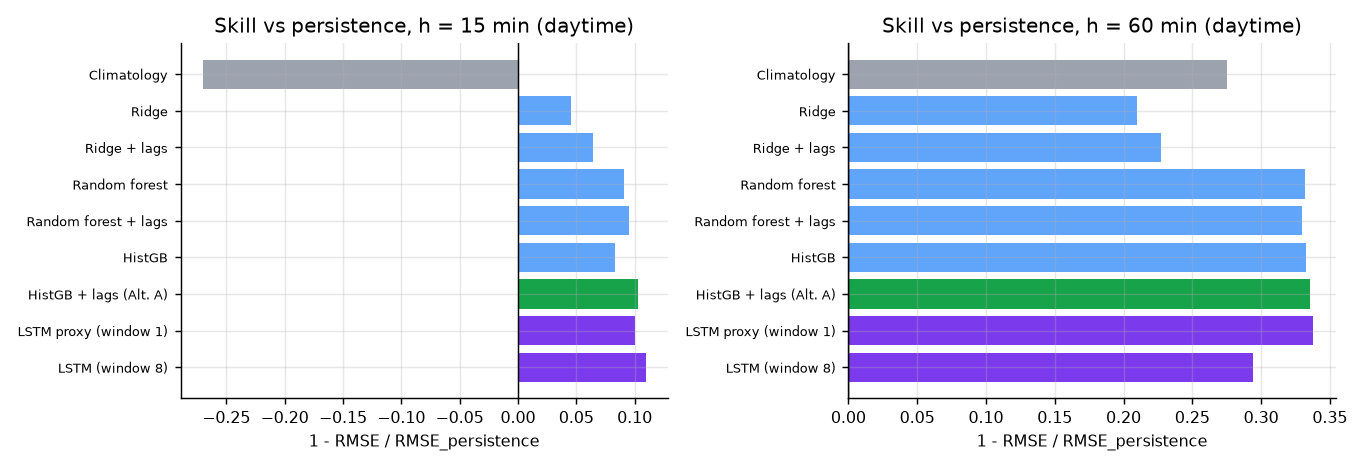

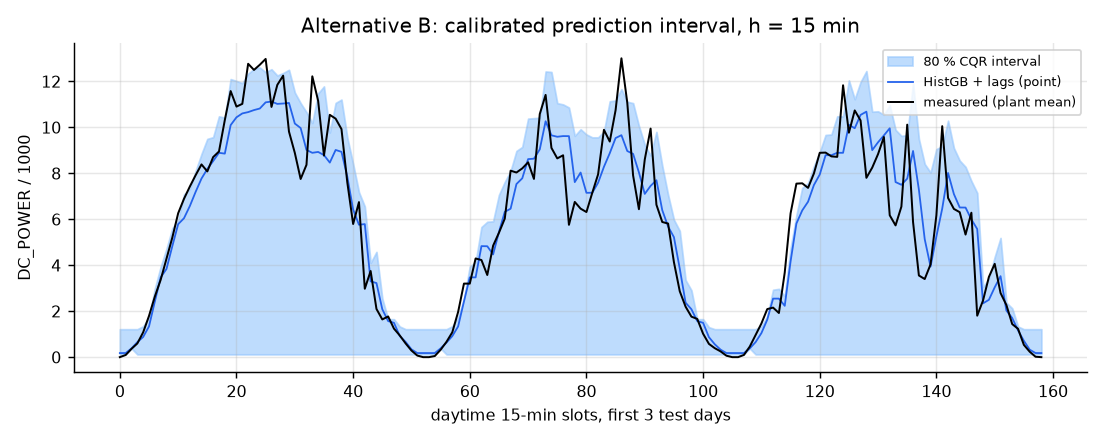

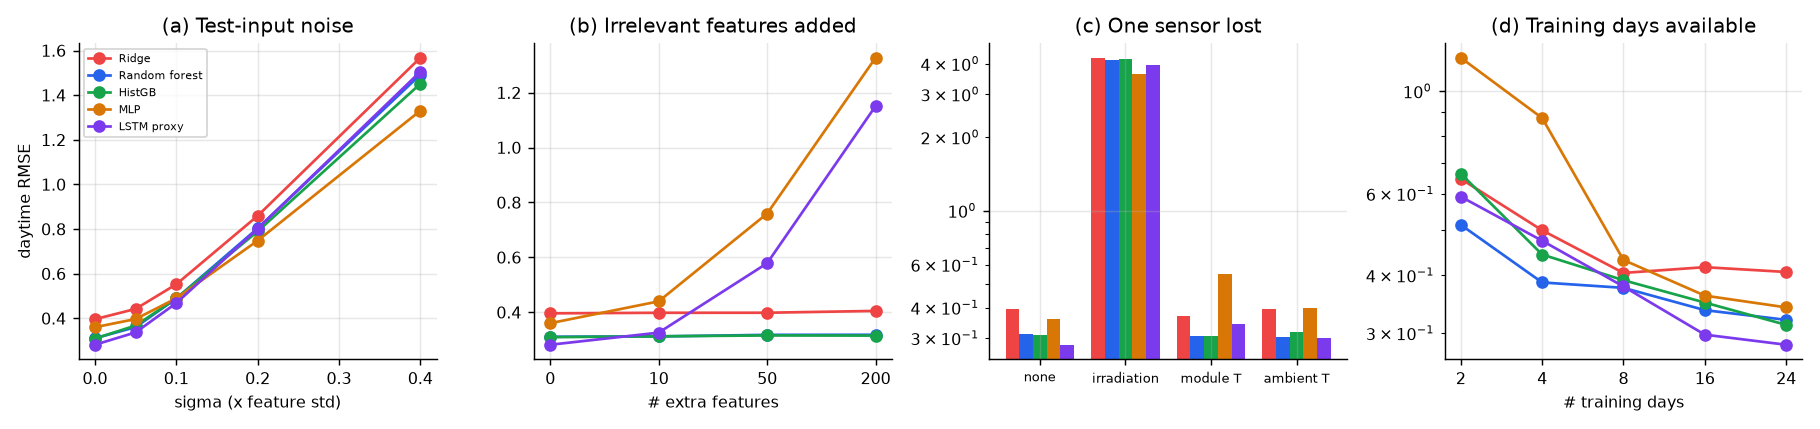

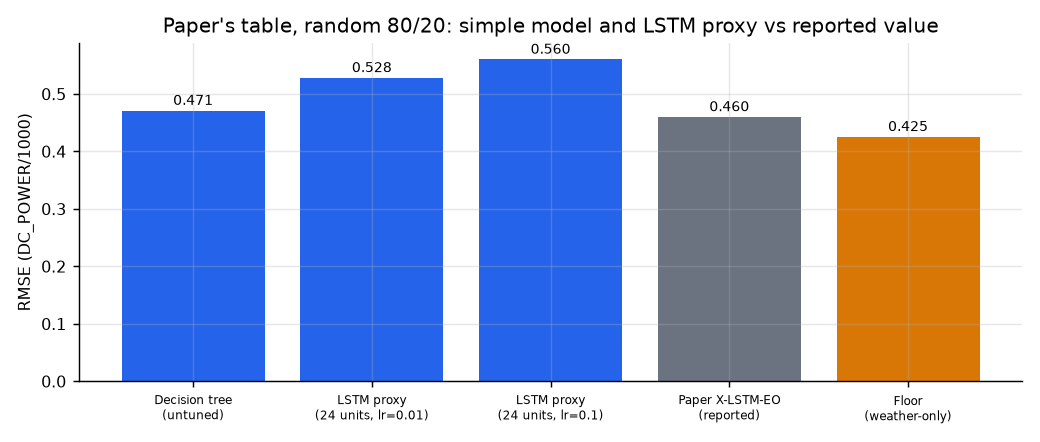

In [ ]:
COL = {"Ridge": "#ef4444", "Random forest": "#2563eb", "HistGB": "#16a34a", "MLP": "#d97706", "LSTM proxy": "#7c3aed"}
# Fig A: forecast skill (daytime) h=1 and h=4
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
for a, h in zip(ax, (1, 4)):
    T = FC[h]["T"].drop("Persistence"); labs = list(T.index)
    cols = ["#9ca3af" if "Climatology" in l else ("#16a34a" if "Alt. A" in l else ("#7c3aed" if "LSTM" in l else "#60a5fa")) for l in labs]
    a.barh(range(len(T)), T.skill_vs_persistence.values, color=cols); a.set_yticks(range(len(T))); a.set_yticklabels(labs, fontsize=7)
    a.axvline(0, color="k", lw=.8); a.set_title(f"Skill vs persistence, h = {15*h} min (daytime)"); a.set_xlabel("1 - RMSE / RMSE_persistence"); a.invert_yaxis()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_p3_skill.png")); plt.close()
# Fig B: prediction intervals on test days (h=1)
q = Q[1]; f = q["f"]; tm = q["tm"]; idx = f.index[tm]; yt = f.target.values[tm]
lo, hi = q["ints"]["CQR (calibrated on val days)"]; first = idx.normalize() == idx.normalize()[0]
fig, ax = plt.subplots(figsize=(8.5, 3.4)); xs = np.arange(first.sum() * 3)
sel = np.arange(len(idx))[:first.sum() * 3]
ax.fill_between(sel, lo[sel], hi[sel], color="#93c5fd", alpha=.6, label="80 % CQR interval"); ax.plot(sel, q["pt"][sel], color="#2563eb", lw=1, label="HistGB + lags (point)")
ax.plot(sel, yt[sel], "k", lw=1.1, label="measured (plant mean)"); ax.set_xlabel("daytime 15-min slots, first 3 test days"); ax.set_ylabel("DC_POWER / 1000"); ax.legend(fontsize=7)
ax.set_title("Alternative B: calibrated prediction interval, h = 15 min"); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_p3_intervals.png")); plt.close()
# Fig C: stress tests, 4 panels
fig, ax = plt.subplots(1, 4, figsize=(14, 3.3))
for n in STRESS:
    ax[0].plot(NOISE.index, NOISE[n], marker="o", color=COL[n], label=n); ax[1].plot(range(len(DIM)), DIM[n], marker="o", color=COL[n])
    ax[3].plot(range(len(SCAR)), SCAR[n], marker="o", color=COL[n])
ax[0].set_title("(a) Test-input noise"); ax[0].set_xlabel("sigma (x feature std)"); ax[0].set_ylabel("daytime RMSE"); ax[0].legend(fontsize=6)
ax[1].set_title("(b) Irrelevant features added"); ax[1].set_xticks(range(len(DIM))); ax[1].set_xticklabels(DIM.index); ax[1].set_xlabel("# extra features")
ax[3].set_title("(d) Training days available"); ax[3].set_xticks(range(len(SCAR))); ax[3].set_xticklabels(SCAR.index); ax[3].set_xlabel("# training days"); ax[3].set_yscale("log")
w_ = 0.16
for i, n in enumerate(STRESS): ax[2].bar(np.arange(len(OUT)) + (i - 2) * w_, OUT[n], w_, color=COL[n])
ax[2].set_xticks(range(len(OUT))); ax[2].set_xticklabels(["none", "irradiation", "module T", "ambient T"], fontsize=7); ax[2].set_title("(c) One sensor lost"); ax[2].set_yscale("log")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_p3_stress.png")); plt.close()
# Fig D: paper's table - LSTM proxy vs simple models vs floor
t = E1_tab["RMSE"]["mean"]; labs = list(t.index) + ["Paper X-LSTM-EO\n(reported)", "Floor\n(weather-only)"]
vals = list(t.values) + [0.46, floor_paper]
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.bar(range(len(vals)), vals, color=["#2563eb"] * len(t) + ["#6b7280", "#d97706"])
[ax.text(i, v + .01, f"{v:.3f}", ha="center", fontsize=8) for i, v in enumerate(vals)]
ax.set_xticks(range(len(vals))); ax.set_xticklabels([l.replace(" (", "\n(") for l in labs], fontsize=6.5); ax.set_ylabel("RMSE (DC_POWER/1000)")
ax.set_title("Paper's table, random 80/20: simple model and LSTM proxy vs reported value"); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_p3_paper_table.png")); plt.close()

## 7. Save every number used in the report

In [ ]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
RES["env"] = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__, "torch": torch.__version__}
with open(os.path.join(OUT_DIR, "results.json"), "w") as fh: json.dump(clean(RES), fh, indent=1)
log("done - results.json written to", OUT_DIR)

[  1758s] done - results.json written to outputs/
